# Learning rate в собственном Batch Gradient Descent

Четыре запуска простого `GradientDescentMse` на пяти синтетических точках, без Taxi CSV. Каждая модель начинает с w=1, b=1; bias добавляется явно.

Общие параметры: threshold=1e-24, max_iterations=200. Сравниваем фактически выполненные шаги, веса и MSE. Малое изменение MSE — исходный критерий остановки, не доказательство достижения минимума. Статусов и отката в классе нет: каждый сохранённый шаг является выполненным обновлением.

Лимит 200 позволяет показать рост ошибки при η=0.6 без переполнения. При η=0.01 за этот лимит минимум может ещё не быть достигнут. Запуск: целевая `.venv`, Restart Kernel / Run All. [README.md](README.md).

In [5]:
import os
import sys
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "02-machine-learning/04-gradient-descent/gradient_descent_mse.py").is_file()
)
module_dir = project_root / "02-machine-learning/04-gradient-descent"
assert Path(sys.prefix).resolve() == (project_root / ".venv").resolve(), "Select the target repository .venv"
assert not any("KarpovCourse" in p for p in sys.path), "Remove the old project's PYTHONPATH"
assert "KarpovCourse" not in os.environ.get("PYTHONPATH", "")
sys.dont_write_bytecode = True
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))

from gradient_descent_mse import GradientDescentMse

print("Python:", sys.version.split()[0])
print("Packages:", {name: version(name) for name in ["numpy", "pandas", "tqdm", "matplotlib"]})
print("Environment: target repository .venv; no KarpovCourse imports")

Python: 3.13.5
Packages: {'numpy': '2.5.4', 'pandas': '3.1.1', 'tqdm': '4.70.1', 'matplotlib': '3.11.2'}
Environment: target repository .venv; no KarpovCourse imports


На этих данных среднее x равно 0, среднее x² равно 2. Поэтому

$$L(w,b)=2(w-3)^2+(b-2)^2,$$

а гессиан равен diag(4, 2). Ошибки параметров на каждом шаге умножаются на (1−4η) и (1−2η). Оба множителя должны иметь модуль меньше 1: для этой задачи устойчивый диапазон — 0 < η < 0.5.

При η=0.4 ошибка наклона меняет знак, но уменьшается; MSE при этом может убывать монотонно. При η=0.6 множитель наклона равен −1.4, поэтому ошибка наклона растёт. Мы показываем только фактически выполненные шаги до общего лимита, без отката и продолжения траектории за пределы запуска.

In [6]:
X = pd.DataFrame({"x": [-2., -1., 0., 1., 2.]})
y = 3 * X["x"] + 2
learning_rates = [0.01, 0.1, 0.4, 0.6]
settings = dict(threshold=1e-24, max_iterations=200)
assert X.shape == (5, 1) and y.shape == (5,)
assert np.isfinite(X.to_numpy()).all() and np.isfinite(y.to_numpy()).all()
print("Samples:", len(X), "; missing values:", int(X.isna().sum().sum()))
display(pd.DataFrame({"x": X["x"], "y": y}))

Samples: 5 ; missing values: 0


,x,y
0,-2.0,-4.0
1,-1.0,-1.0
2,0.0,2.0
3,1.0,5.0
4,2.0,8.0


In [7]:
runs = {}
rows = []
for lr in learning_rates:
    model = GradientDescentMse(X, y, learning_rate=lr, copy=True, **settings)
    model.add_constant_feature()
    assert list(model.samples.columns) == ["x", "constant"]
    np.testing.assert_array_equal(model.samples["constant"], np.ones(len(X)))
    np.testing.assert_array_equal(model.beta, [1., 1.])
    model.learn(show_progress=False)
    runs[lr] = model
    history = model.iteration_loss_dict
    steps = max(history)
    last_change = abs(history[steps] - history[steps - 1])
    rows.append({
        "learning_rate": lr,
        "steps": steps,
        "w": model.beta[0],
        "b": model.beta[1],
        "final_MSE": model.calculate_mse_loss(),
        "end_condition": "MSE change < threshold" if last_change < settings["threshold"] else "iteration limit",
    })
    assert list(history) == list(range(steps + 1))
    assert np.isclose(history[steps], model.calculate_mse_loss())

assert list(X.columns) == ["x"], "copy=True must preserve the original DataFrame"
summary = pd.DataFrame(rows).set_index("learning_rate")
with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(summary)

,steps,w,b,final_MSE,end_condition
learning_rate,,,,,
0.01,200,2.9994307846e+00,1.9824120534e+00,3.0998387804e-04,iteration limit
0.10,123,3.0000000000e+00,2.0000000000e+00,1.4460180508e-24,MSE change < threshold
0.40,57,3.0000000000e+00,2.0000000000e+00,4.0996332105e-25,MSE change < threshold
0.60,200,-3.3623051926e+29,1.0802918899e+13,2.2610192417e+59,iteration limit


In [8]:
# Compare stable runs with the recurrence in exact arithmetic.
for lr in [0.01, 0.1, 0.4]:
    model = runs[lr]
    steps = max(model.iteration_loss_dict)
    expected = [3 - 2 * (1 - 4 * lr) ** steps, 2 - (1 - 2 * lr) ** steps]
    np.testing.assert_allclose(model.beta, expected, rtol=1e-10, atol=1e-12)
    losses = np.array(list(model.iteration_loss_dict.values()))
    assert (np.diff(losses) <= 1e-12).all()

for model in runs.values():
    assert np.isfinite(list(model.iteration_loss_dict.values())).all()
# For a divergent run, check growth rather than accurate coefficients:
# huge residuals amplify floating-point cancellation in the bias gradient.
np.testing.assert_allclose(runs[0.6].iteration_loss_dict[1], 15.72)
assert runs[0.6].iteration_loss_dict[200] > runs[0.6].iteration_loss_dict[0]
print("Stable runs agree with the recurrence; lr=0.6 increases MSE.")

Stable runs agree with the recurrence; lr=0.6 increases MSE.


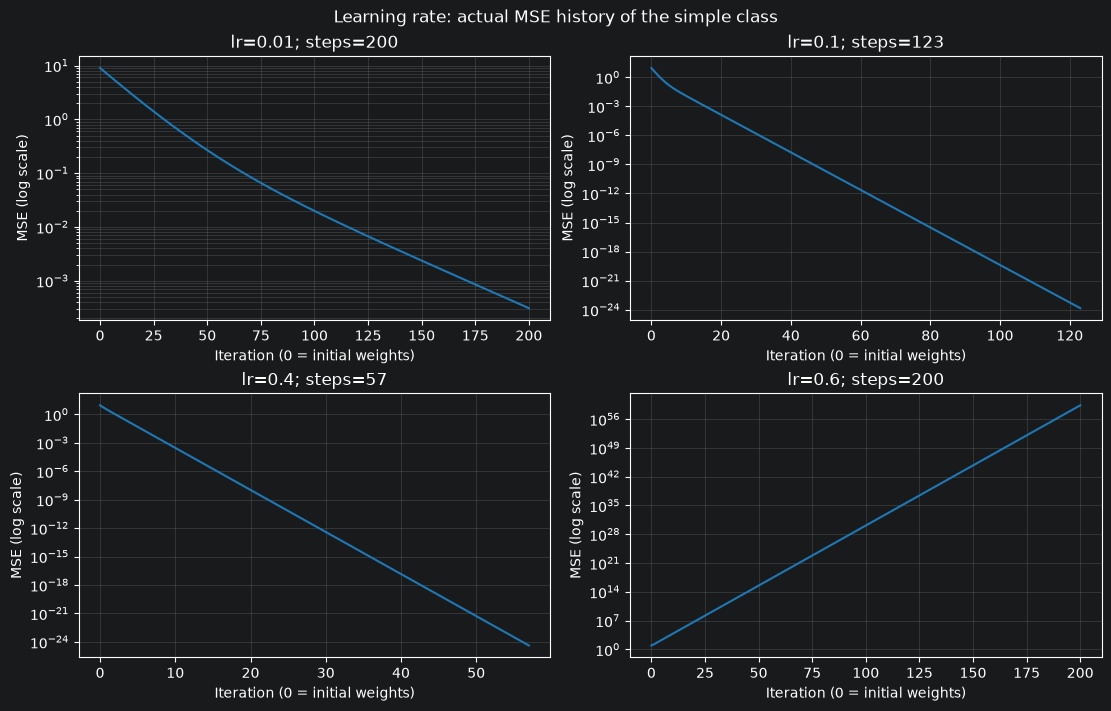

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for ax, (lr, model) in zip(axes.flat, runs.items()):
    history = model.iteration_loss_dict
    ax.plot(list(history), list(history.values()), color="tab:blue")
    ax.set_yscale("log")
    ax.set_xlabel("Iteration (0 = initial weights)")
    ax.set_ylabel("MSE (log scale)")
    ax.set_title(f"lr={lr}; steps={max(history)}")
    ax.grid(True, which="both", alpha=0.25)
fig.suptitle("Learning rate: actual MSE history of the simple class")
plt.show()

## Интерпретация

При η=0.01 ошибка убывает медленно: за 200 шагов веса ещё не обязаны достичь [3,2]. При η=0.1 и 0.4 убывание быстрее. При η=0.6 ошибка растёт; класс не отклоняет шаги, поэтому график показывает всю фактически рассчитанную историю до лимита. При столь больших остатках ошибки округления и взаимное вычитание чисел также искажают bias: его финальное значение в расходящемся запуске нельзя трактовать как точную оценку коэффициента.

Это сравнение на пяти точных точках, не измерение времени и не оценка обобщающей способности. Остановка по малому изменению MSE не является отдельным статусом сходимости. Числа в таблице получаются при Run All; конкретные выводы о числе шагов следует читать вместе с заданными threshold и max_iterations. При изменении масштаба признаков устойчивый диапазон learning rate изменится.